<sub>**The Annotated ML Handbook** · Part V: scikit-learn · by Mahir Absar Khan</sub>

# Chapter 25: Interpreting, explaining and saving models

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-5-scikit-learn/25-sklearn-interpret.ipynb) &nbsp; [📚 Contents](../../book/README.md) &nbsp; [🌐 Web edition](https://mahir-606.github.io/annotated-ml-handbook/)

*Run the setup cell first, then read and run the cells from top to bottom. Every code cell is followed by a table explaining what each line does.*

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

A model that predicts well is only half the job in research. Reviewers and colleagues will ask *which features matter*, *how* they affect predictions, and whether the model can be reused. This chapter covers built-in importances and their pitfalls, permutation importance, partial dependence, SHAP, and persisting models safely.

## 25.1 Set-up · *Beginner*

**A random forest on the insurance data**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

ins = pd.read_csv("insurance.csv")
rng = np.random.default_rng(0)
ins["noise"] = rng.normal(size=len(ins))
X, y = ins.drop(columns="charges"), ins["charges"]
X = X.astype({"age": float, "children": float})
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0)
pre = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), ["age", "bmi", "children", "noise"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), ["sex", "smoker", "region"]),
], verbose_feature_names_out=False)
rf = Pipeline([("pre", pre), ("m", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1))])
rf.fit(X_tr, y_tr)
print("test R2:", round(rf.score(X_te, y_te), 3))

test R2: 0.928


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import numpy as np</code></td><td>Import NumPy (the array library) under the short name <code>np</code>.</td></tr>
<tr><td><code>import pandas as pd</code></td><td>Import pandas (the table library) under the short name <code>pd</code>.</td></tr>
<tr><td><code>import matplotlib.pyplot as plt</code></td><td>Import Matplotlib&#x27;s plotting interface under the short name <code>plt</code>.</td></tr>
<tr><td><code>from sklearn.model_selection import train_test_split</code></td><td>Import <code>train_test_split</code> from scikit-learn&#x27;s <code>model_selection</code> module.</td></tr>
<tr><td><code>from sklearn.compose import ColumnTransformer</code></td><td>Import <code>ColumnTransformer</code> from scikit-learn&#x27;s <code>compose</code> module.</td></tr>
<tr><td><code>from sklearn.pipeline import Pipeline</code></td><td>Import <code>Pipeline</code> from scikit-learn&#x27;s <code>pipeline</code> module.</td></tr>
<tr><td><code>from sklearn.preprocessing import OneHotEncoder</code></td><td>Import <code>OneHotEncoder</code> from scikit-learn&#x27;s <code>preprocessing</code> module.</td></tr>
<tr><td><code>from sklearn.impute import SimpleImputer</code></td><td>Import <code>SimpleImputer</code> from scikit-learn&#x27;s <code>impute</code> module.</td></tr>
<tr><td><code>from sklearn.ensemble import RandomForestRegressor</code></td><td>Import <code>RandomForestRegressor</code> from scikit-learn&#x27;s <code>ensemble</code> module.</td></tr>
<tr><td><code>ins = pd.read_csv(&quot;insurance.csv&quot;)</code></td><td>Load the practice dataset.</td></tr>
<tr><td><code>rng = np.random.default_rng(0)</code></td><td>Seeded generator.</td></tr>
<tr><td><code>ins[&quot;noise&quot;] = rng.normal(size=len(ins))</code></td><td>A pure-noise feature: a good method should rank it near the bottom.</td></tr>
<tr><td><code>X, y = ins.drop(columns=&quot;charges&quot;), ins[&quot;charges&quot;]</code></td><td>Features and target.</td></tr>
<tr><td><code>X = X.astype({&quot;age&quot;: float, &quot;children&quot;: float})</code></td><td>Integer columns -&gt; float. Partial dependence plots refuse integer data (see the Bug hunt box below).</td></tr>
<tr><td><code>X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0)</code></td><td>75/25 split.</td></tr>
<tr><td><code>pre = ColumnTransformer([</code></td><td>Preprocessing:</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;(&quot;num&quot;, SimpleImputer(strategy=&quot;median&quot;), [&quot;age&quot;, &quot;bmi&quot;, &quot;children&quot;, &quot;noise&quot;]),</code></td><td>Numeric columns: impute only (trees don&#x27;t need scaling).</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;(&quot;cat&quot;, OneHotEncoder(handle_unknown=&quot;ignore&quot;, drop=&quot;if_binary&quot;), [&quot;sex&quot;, &quot;smoker&quot;, &quot;region&quot;]),</code></td><td>Categorical columns: one-hot encode.</td></tr>
<tr><td><code>], verbose_feature_names_out=False)</code></td><td>Keep plain names (&quot;age&quot; instead of &quot;num__age&quot;).</td></tr>
<tr><td><code>rf = Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1))])</code></td><td>Preprocessing + random forest.</td></tr>
<tr><td><code>rf.fit(X_tr, y_tr)</code></td><td>Train.</td></tr>
<tr><td><code>print(&quot;test R2:&quot;, round(rf.score(X_te, y_te), 3))</code></td><td>Test performance.</td></tr>
</table>
</details>

## 25.2 Impurity-based feature importance · *Intermediate*

> **📖 Definitions**
>
> **Feature importance**: a score of how much a model relies on each feature.


Tree ensembles expose `feature_importances_`: how much each feature reduced the splitting criterion, summed over all trees. It is free to compute but has known biases.

**feature_importances_**

In [3]:
names = rf.named_steps["pre"].get_feature_names_out()
imp = pd.Series(rf.named_steps["m"].feature_importances_, index=names).sort_values(ascending=False)
print(imp.round(4))

smoker_yes          0.8407
age                 0.1266
bmi                 0.0182
noise               0.0065
children            0.0036
sex_male            0.0015
region_southwest    0.0012
region_northeast    0.0007
region_southeast    0.0007
region_northwest    0.0005
dtype: float64


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>names = rf.named_steps[&quot;pre&quot;].get_feature_names_out()</code></td><td>Names after one-hot encoding.</td></tr>
<tr><td><code>imp = pd.Series(rf.named_steps[&quot;m&quot;].feature_importances_, index=names).sort_values(ascending=False)</code></td><td>Pair importances with names, largest first.</td></tr>
<tr><td><code>print(imp.round(4))</code></td><td>Importances sum to 1.</td></tr>
</table>
</details>

> **⚠️ Pitfall** · **Impurity importance is biased**
>
> It is computed on *training* data, and it favours continuous, high-cardinality features, which offer many possible split points. Notice that the pure-noise column outranks `children`, `sex` and every region column above. Prefer **permutation importance on held-out data** for conclusions.

## 25.3 Permutation importance · *Intermediate*

> **📖 Definitions**
>
> **Permutation importance**: the drop in a model's score when one feature's values are randomly shuffled, which breaks its link with the target.


Shuffle one feature's values in the test set and measure how much the score drops. If the model relied on that feature, performance falls; if not, nothing changes. It is model-agnostic and computed on held-out data.

**Permutation importance on the test set**

            mean      sd
smoker    1.6078  0.1436
age       0.2830  0.0224
bmi       0.0232  0.0035
children  0.0053  0.0013
sex       0.0002  0.0005
region    0.0002  0.0006
noise    -0.0000  0.0014


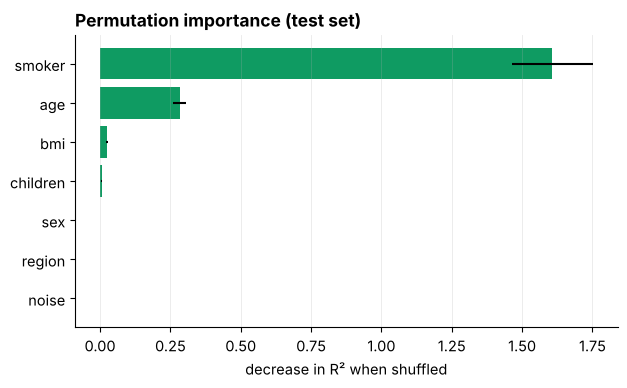

In [4]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(rf, X_te, y_te, n_repeats=20, random_state=0, scoring="r2", n_jobs=-1)
pim = pd.DataFrame({"mean": pi.importances_mean, "sd": pi.importances_std}, index=X_te.columns).sort_values("mean")
print(pim.round(4).iloc[::-1])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(pim.index, pim["mean"], xerr=pim["sd"], color="#0f9b62")
ax.set(xlabel="decrease in R² when shuffled", title="Permutation importance (test set)")
ax.grid(axis="y", visible=False)
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.inspection import permutation_importance</code></td><td>Import <code>permutation_importance</code> from scikit-learn&#x27;s <code>inspection</code> module.</td></tr>
<tr><td><code>pi = permutation_importance(rf, X_te, y_te, n_repeats=20, random_state=0, scoring=&quot;r2&quot;, n_jobs=-1)</code></td><td>Permutes RAW input columns, before preprocessing.</td></tr>
<tr><td><code>pim = pd.DataFrame({&quot;mean&quot;: pi.importances_mean, &quot;sd&quot;: pi.importances_std}, index=X_te.columns).sort_values(&quot;mean&quot;)</code></td><td>Mean and SD of the score drop per feature.</td></tr>
<tr><td><code>print(pim.round(4).iloc[::-1])</code></td><td>Largest first.</td></tr>
<tr><td><code>fig, ax = plt.subplots(figsize=(7, 3.8))</code></td><td>One panel.</td></tr>
<tr><td><code>ax.barh(pim.index, pim[&quot;mean&quot;], xerr=pim[&quot;sd&quot;], color=&quot;#0f9b62&quot;)</code></td><td>Horizontal bars with error bars.</td></tr>
<tr><td><code>ax.set(xlabel=&quot;decrease in R² when shuffled&quot;, title=&quot;Permutation importance (test set)&quot;)</code></td><td>Labels.</td></tr>
<tr><td><code>ax.grid(axis=&quot;y&quot;, visible=False)</code></td><td>Keep only vertical grid lines.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

> **📝 Note** · **Correlated features share importance**
>
> If two features carry the same information, shuffling one barely hurts because the model uses the other. Both then look unimportant. Check correlations first, and consider permuting correlated groups together.

## 25.4 Partial dependence and ICE plots · *Intermediate*

> **📖 Definitions**
>
> **Partial dependence plot (PDP)**: the model's average prediction as one feature varies, with the other features averaged out.
>
> **ICE plot (individual conditional expectation)**: one line per sample showing how its prediction changes as one feature varies.


A **partial dependence plot (PDP)** shows the average predicted outcome as one feature varies, averaging over the others. **ICE** lines show the same for individual samples, revealing heterogeneity.

**How do age and BMI affect predicted charges?**

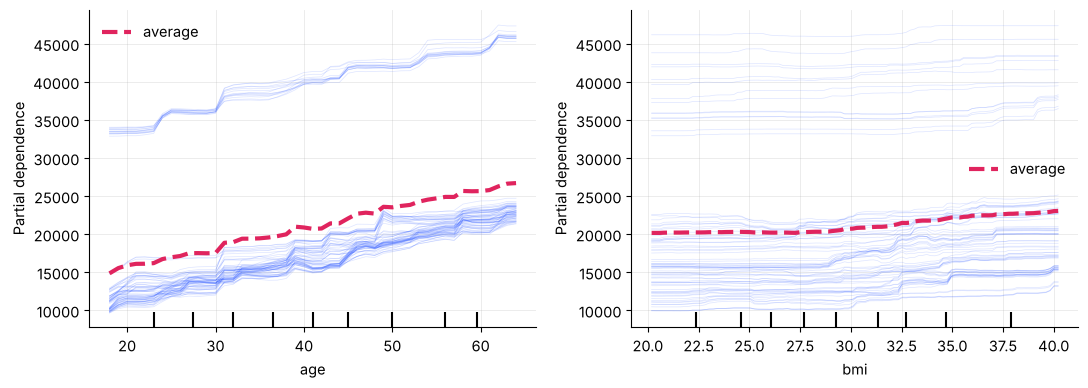

In [5]:
from sklearn.inspection import PartialDependenceDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
PartialDependenceDisplay.from_estimator(rf, X_te, features=["age", "bmi"], kind="both",
                                        subsample=80, random_state=0, ax=axes,
                                        ice_lines_kw={"alpha": 0.15}, pd_line_kw={"color": "#e0245e", "lw": 3})
plt.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.inspection import PartialDependenceDisplay</code></td><td>Import <code>PartialDependenceDisplay</code> from scikit-learn&#x27;s <code>inspection</code> module.</td></tr>
<tr><td><code>fig, axes = plt.subplots(1, 2, figsize=(11, 4))</code></td><td>Two panels.</td></tr>
<tr><td><code>PartialDependenceDisplay.from_estimator(rf, X_te, features=[&quot;age&quot;, &quot;bmi&quot;], kind=&quot;both&quot;,</code></td><td>&quot;both&quot; = PDP + ICE lines.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;subsample=80, random_state=0, ax=axes,</code></td><td>Draw ICE lines for 80 random customers...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;ice_lines_kw={&quot;alpha&quot;: 0.15}, pd_line_kw={&quot;color&quot;: &quot;#e0245e&quot;, &quot;lw&quot;: 3})</code></td><td>...faint ICE lines, bold PDP line.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Adjust spacing so titles and labels don&#x27;t overlap.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

**Two-way partial dependence**

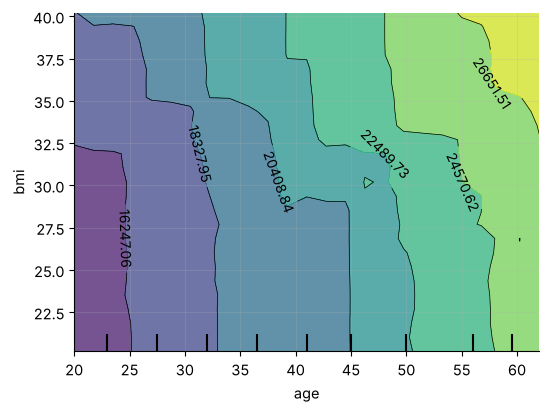

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.4))
PartialDependenceDisplay.from_estimator(rf, X_te, features=[("age", "bmi")], grid_resolution=25, ax=ax)
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, ax = plt.subplots(figsize=(6, 4.4))</code></td><td>One panel.</td></tr>
<tr><td><code>PartialDependenceDisplay.from_estimator(rf, X_te, features=[(&quot;age&quot;, &quot;bmi&quot;)], grid_resolution=25, ax=ax)</code></td><td>A tuple of two features gives a 2-D contour; a coarser grid keeps it fast (default 100x100 = 10,000 points).</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

> **📝 Note** · **Categorical features in partial dependence**
>
> For a categorical feature on its own, pass `categorical_features=["smoker"]` to get a bar per category. Two-way plots that mix a continuous and a categorical feature are not supported. Instead, draw one-way ICE plots coloured by group, or compare PDPs computed on each subgroup.

## 25.5 SHAP values · *Advanced*

> **📖 Definitions**
>
> **SHAP value**: the contribution of one feature to one prediction, based on Shapley values from game theory. A sample's SHAP values add up to its prediction minus the average prediction.


**SHAP** (SHapley Additive exPlanations) splits each individual prediction into additive contributions from each feature, grounded in cooperative game theory. It gives both local explanations (one prediction) and global summaries. It lives in the separate `shap` package (`pip install shap`).

**SHAP for a tree model (requires the shap package)**

*Shown for reference, not run automatically (it waits for input, needs your own files, or would change your system). Copy it into a cell to try it.*

```python
import shap

pre_fitted, model = rf.named_steps["pre"], rf.named_steps["m"]
X_te_t = pd.DataFrame(pre_fitted.transform(X_te), columns=pre_fitted.get_feature_names_out())
explainer = shap.TreeExplainer(model)
sv = explainer(X_te_t)
shap.plots.beeswarm(sv)
shap.plots.waterfall(sv[0])
```

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import shap</code></td><td>pip install shap</td></tr>
<tr><td><code>pre_fitted, model = rf.named_steps[&quot;pre&quot;], rf.named_steps[&quot;m&quot;]</code></td><td>The fitted preprocessor and the forest.</td></tr>
<tr><td><code>X_te_t = pd.DataFrame(pre_fitted.transform(X_te), columns=pre_fitted.get_feature_names_out())</code></td><td>SHAP explains the model on the TRANSFORMED features.</td></tr>
<tr><td><code>explainer = shap.TreeExplainer(model)</code></td><td>Fast, exact algorithm for tree ensembles.</td></tr>
<tr><td><code>sv = explainer(X_te_t)</code></td><td>An Explanation object: one row of contributions per sample.</td></tr>
<tr><td><code>shap.plots.beeswarm(sv)</code></td><td>Global view: each dot is one sample&#x27;s contribution for one feature.</td></tr>
<tr><td><code>shap.plots.waterfall(sv[0])</code></td><td>Local view: how each feature moved sample 0 from the average prediction.</td></tr>
</table>
</details>

> **🔬 Research practice** · **Interpretation claims need care**
>
> Importance and SHAP describe **the model**, not the world. A feature can be important because it is a proxy for something else, because of leakage, or because of a quirk of the sample. Validate interpretations with domain knowledge, stability across CV folds and seeds, and if possible on external data. Avoid causal language ("X causes Y") unless your design supports it.

## 25.6 Saving and loading models · *Beginner*

> **📖 Definitions**
>
> **Serialization**: saving an object, such as a fitted model, to a file so it can be loaded later. `joblib` and `pickle` do this in Python.


Save the **whole fitted pipeline**, so preprocessing travels with the model.

**joblib: the standard way**

In [7]:
import joblib, sklearn, json, platform

joblib.dump(rf, "insurance_rf.joblib")
loaded = joblib.load("insurance_rf.joblib")
print(np.allclose(loaded.predict(X_te), rf.predict(X_te)))
meta = {"sklearn": sklearn.__version__, "python": platform.python_version(),
        "features": list(X.columns), "test_r2": round(rf.score(X_te, y_te), 4)}
with open("insurance_rf.meta.json", "w") as f:
    json.dump(meta, f, indent=2)
print(meta)

True
{'sklearn': '1.9.1', 'python': '3.13.18', 'features': ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'noise'], 'test_r2': 0.928}


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import joblib, sklearn, json, platform</code></td><td>Import joblib, used to save and load fitted models and scikit-learn and the standard-library <code>json</code> module and the <code>platform</code> module (system and version info).</td></tr>
<tr><td><code>joblib.dump(rf, &quot;insurance_rf.joblib&quot;)</code></td><td>Serialise the fitted pipeline to disk (compress=3 makes smaller files).</td></tr>
<tr><td><code>loaded = joblib.load(&quot;insurance_rf.joblib&quot;)</code></td><td>Load it back later, or on another machine.</td></tr>
<tr><td><code>print(np.allclose(loaded.predict(X_te), rf.predict(X_te)))</code></td><td>Identical predictions.</td></tr>
<tr><td><code>meta = {&quot;sklearn&quot;: sklearn.__version__, &quot;python&quot;: platform.python_version(),</code></td><td>Metadata to store next to the model...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&quot;features&quot;: list(X.columns), &quot;test_r2&quot;: round(rf.score(X_te, y_te), 4)}</code></td><td>...the expected input columns and the test score.</td></tr>
<tr><td><code>with open(&quot;insurance_rf.meta.json&quot;, &quot;w&quot;) as f:</code></td><td>Open a JSON file for writing.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;json.dump(meta, f, indent=2)</code></td><td>Record versions and inputs beside the model file.</td></tr>
<tr><td><code>print(meta)</code></td><td>Display the value of <code>meta</code>.</td></tr>
</table>
</details>

> **⚠️ Pitfall** · **Pickles are version-specific and unsafe**
>
> A model saved with one scikit-learn version may not load (or may behave differently) under another, so record versions as above. **Never load a `.joblib`/`.pkl` file from an untrusted source**: unpickling can execute arbitrary code. For long-term or cross-language deployment, consider the `skops` format or exporting to ONNX (`skl2onnx`).

> **🐞 Bug hunt** · **`ValueError: The column 0 contains integer data. Partial dependence plots are not supported for integer data`**
>
> Recent scikit-learn versions refuse to compute partial dependence on integer columns, because the grid of values would be silently rounded. Convert those columns to float first: `X = X.astype({"age": float})`. That is why the set-up code above casts `age` and `children`.

> **✍️ Try it yourself**
>
> 1. Compute permutation importance with `scoring="neg_mean_absolute_error"`. Does the ranking change?
> 2. Draw ICE plots for `children`. Is the effect the same for everyone?
> 3. Save a fitted pipeline, restart Python, load it, and predict for a brand-new customer DataFrame.
>
> *Worked solutions:* [solutions-parts-5-8.ipynb](../../solutions/solutions-parts-5-8.ipynb), section *Chapter 25*.

---

⬅️ [Chapter 24: Unsupervised learning: clustering and dimensionality reduction](24-sklearn-unsupervised.ipynb) · [📚 Contents](../../book/README.md) · [Chapter 26: TensorFlow fundamentals: tensors, gradients and data pipelines](../part-6-tensorflow-keras/26-tf-basics.ipynb) ➡️